In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("data/Plant_1_Generation_Data.csv")
df.head()

,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


In [4]:
df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"], format="%d-%m-%Y %H:%M")

Choisir une journée et un seul onduleur :

In [5]:
# La centrale a plusieurs onduleurs, on en prend un seul
un_onduleur = df[df["SOURCE_KEY"] == df["SOURCE_KEY"].iloc[0]]

# On filtre une seule journée
jour = un_onduleur[un_onduleur["DATE_TIME"].dt.date == pd.to_datetime("2020-05-23").date()]

Tracer la courbe:

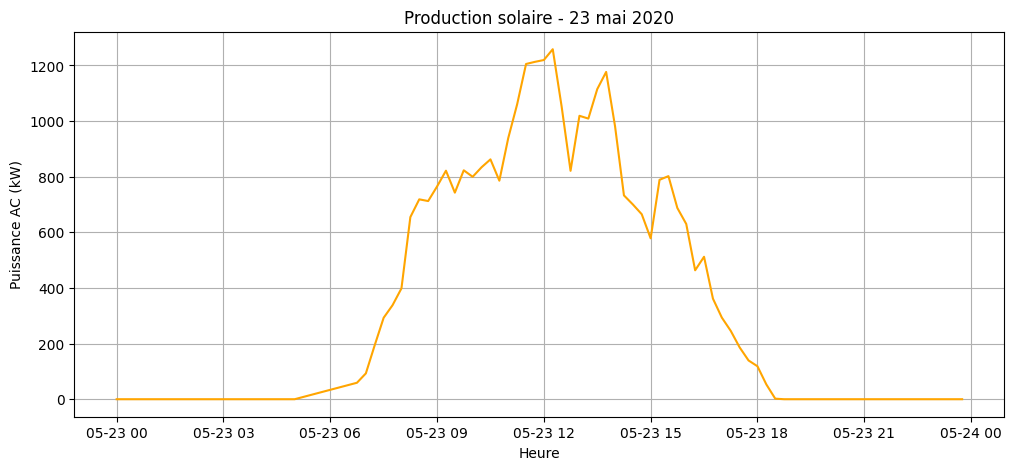

In [6]:
plt.figure(figsize=(12, 5))
plt.plot(jour["DATE_TIME"], jour["AC_POWER"], color="orange")
plt.title("Production solaire - 23 mai 2020")
plt.xlabel("Heure")
plt.ylabel("Puissance AC (kW)") #Panneaux → DC_POWER → [Onduleur] → AC_POWER → Réseau
plt.grid(True)
plt.show()

Charger la météo:

In [7]:
meteo = pd.read_csv("data/Plant_1_Weather_Sensor_Data.csv")
meteo.head()

,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0


In [8]:
meteo["DATE_TIME"] = pd.to_datetime(meteo["DATE_TIME"])

Tracer l'irradiance sur la même journée:

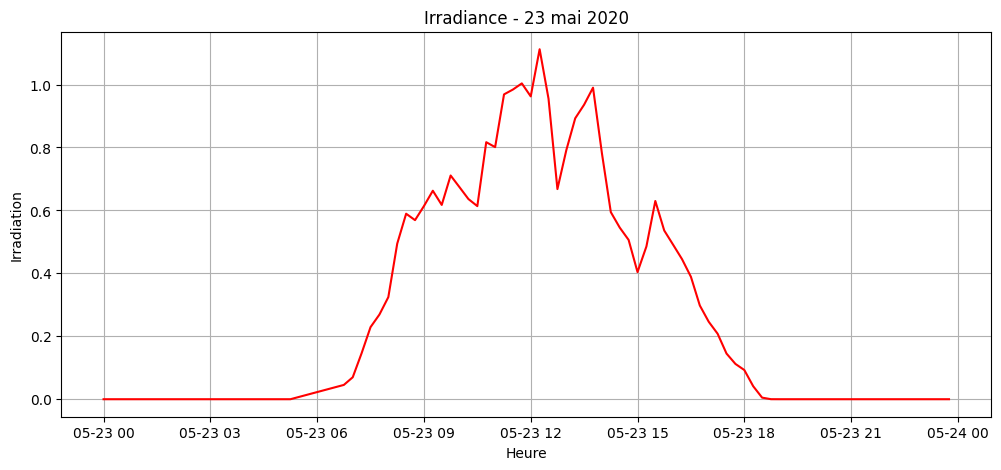

In [9]:
meteo_jour = meteo[meteo["DATE_TIME"].dt.date == pd.to_datetime("2020-05-23").date()]

plt.figure(figsize=(12, 5))
plt.plot(meteo_jour["DATE_TIME"], meteo_jour["IRRADIATION"], color="red")
plt.title("Irradiance - 23 mai 2020")
plt.xlabel("Heure")
plt.ylabel("Irradiation")
plt.grid(True)
plt.show()

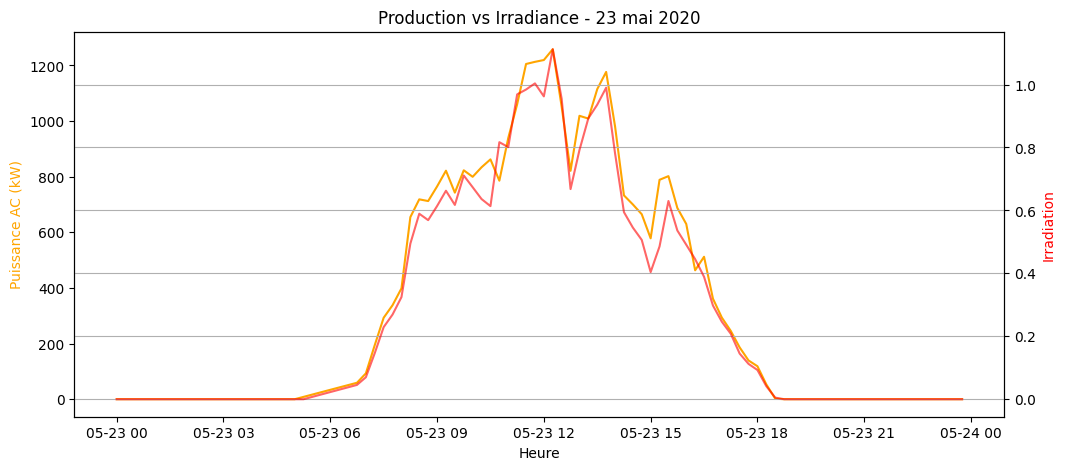

In [9]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Production (axe de gauche)
ax1.plot(jour["DATE_TIME"], jour["AC_POWER"], color="orange", label="Production AC (kW)")
ax1.set_xlabel("Heure")
ax1.set_ylabel("Puissance AC (kW)", color="orange")

# Irradiance (axe de droite)
ax2 = ax1.twinx()
ax2.plot(meteo_jour["DATE_TIME"], meteo_jour["IRRADIATION"], color="red", alpha=0.6, label="Irradiance")
ax2.set_ylabel("Irradiation", color="red")

plt.title("Production vs Irradiance - 23 mai 2020")
plt.grid(True)
plt.show()

Fusionner les deux tableaux: 

In [10]:
df_complet = pd.merge(
    df,               # production
    meteo,            # meteo
     on="DATE_TIME",   # la clé commune
    how="inner"       # garde seulement les horodatages présents dans les DEUX fichiers
)
df_complet.head()

,DATE_TIME,PLANT_ID_x,SOURCE_KEY_x,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,PLANT_ID_y,SOURCE_KEY_y,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
2,2020-05-15,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
3,2020-05-15,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
4,2020-05-15,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0


Mesurer la corrélation :



In [11]:
correlation = df_complet[["AC_POWER", "IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE"]].corr()
print(correlation)

                     AC_POWER  IRRADIATION  AMBIENT_TEMPERATURE  \
AC_POWER             1.000000     0.989340             0.724903   
IRRADIATION          0.989340     1.000000             0.725278   
AMBIENT_TEMPERATURE  0.724903     0.725278             1.000000   
MODULE_TEMPERATURE   0.954924     0.961511             0.855420   

                     MODULE_TEMPERATURE  
AC_POWER                       0.954924  
IRRADIATION                    0.961511  
AMBIENT_TEMPERATURE            0.855420  
MODULE_TEMPERATURE             1.000000  


In [12]:
# calcul du rendement de conversion de l'onduleur
jour_midi = jour[jour["AC_POWER"] > 0]
rendement = jour_midi["AC_POWER"] / jour_midi["DC_POWER"]
print(rendement.describe())

count    48.000000
mean      0.097745
std       0.000417
min       0.095918
25%       0.097591
50%       0.097859
75%       0.097954
max       0.098305
dtype: float64


- Détecté : DC_POWER surévalué ×10 (rendement onduleur apparent de 9,8% au lieu de ~98%)
- Corrigé avec un facteur /10, validé par le calcul de rendement

In [13]:
# Corriger le facteur d'échelle
df["DC_POWER_CORRIGE"] = df["DC_POWER"] / 10

# Vérifier : le rendement doit maintenant être ~0.98
verif = df[df["AC_POWER"] > 0]
print((verif["AC_POWER"] / verif["DC_POWER_CORRIGE"]).describe())

count    36827.000000
mean         0.977189
std          0.004583
min          0.955518
25%          0.975790
50%          0.978451
75%          0.980144
max          1.065922
dtype: float64


- Rendement onduleur validé après correction : 97,7% en moyenne 
- Quelques ratios > 100% détectés → bruit de mesure à faible puissance (aube/crépuscule)
- À filtrer 

In [14]:
suspect = verif[verif["AC_POWER"] / verif["DC_POWER_CORRIGE"] > 1]
print(suspect[["DATE_TIME", "DC_POWER_CORRIGE", "AC_POWER"]].describe())

                 DATE_TIME  DC_POWER_CORRIGE     AC_POWER
count                   18         18.000000    18.000000
mean   2020-06-11 19:40:00        534.238790   547.256746
min    2020-05-22 13:00:00        439.037500   445.828571
25%    2020-06-14 08:30:00        475.328125   481.596429
50%    2020-06-14 08:30:00        481.056250   487.700000
75%    2020-06-14 08:30:00        492.162500   498.896429
max    2020-06-14 08:30:00        990.457143  1055.750000
std                    NaN        165.115968   183.701311


Enquête : que s'est-il passé le 14 juin à 8h30 ?

In [15]:
print(suspect["DATE_TIME"].value_counts())

DATE_TIME
2020-06-14 08:30:00    16
2020-05-22 13:00:00     2
Name: count, dtype: int64


- Hypothèse "bruit à faible puissance" réfutée : les ratios >100% surviennent à ~500 kW
- Découverte : la plupart concentrés au même instant (14/06 08:30) sur plusieurs onduleurs
- Cause probable : décalage d'échantillonnage DC/AC pendant un transitoire rapide (nuage)
- Impact : 18 points / 36 827 → négligeable, décision de filtrage en semaine 2

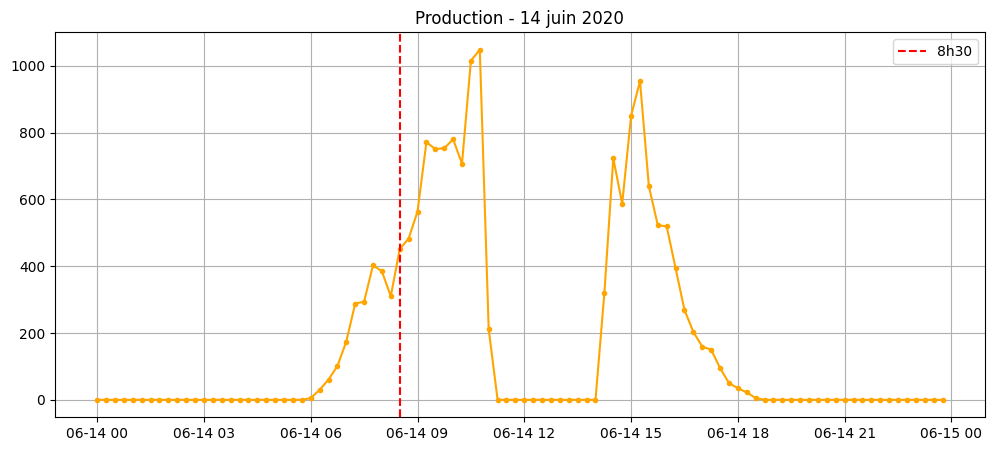

In [16]:
matin = un_onduleur[un_onduleur["DATE_TIME"].dt.date == pd.to_datetime("2020-06-14").date()]

plt.figure(figsize=(12, 5))
plt.plot(matin["DATE_TIME"], matin["AC_POWER"], color="orange", marker="o", markersize=3)
plt.axvline(pd.to_datetime("2020-06-14 08:30"), color="red", linestyle="--", label="8h30")
plt.title("Production - 14 juin 2020")
plt.legend()
plt.grid(True)
plt.show()

Est-ce que le soleil brillait pendant la coupure ?

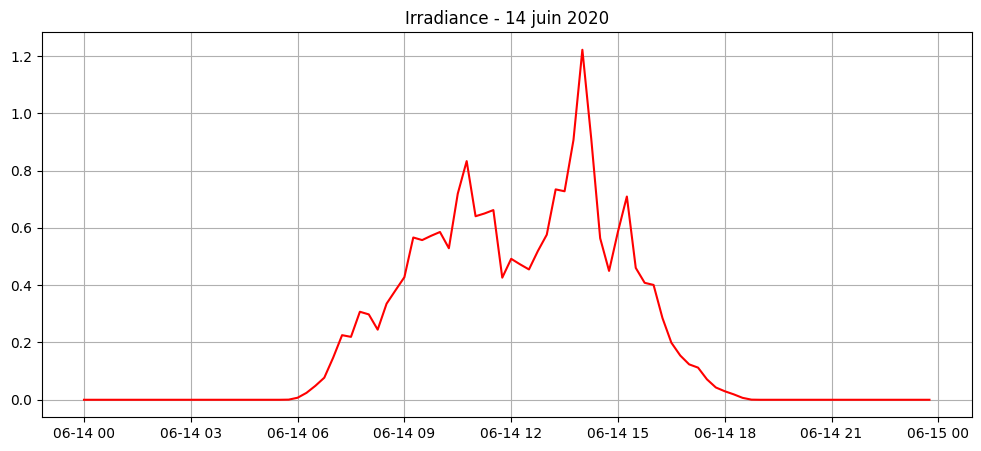

In [17]:
meteo_14 = meteo[meteo["DATE_TIME"].dt.date == pd.to_datetime("2020-06-14").date()]

plt.figure(figsize=(12, 5))
plt.plot(meteo_14["DATE_TIME"], meteo_14["IRRADIATION"], color="red")
plt.title("Irradiance - 14 juin 2020")
plt.grid(True)
plt.show()

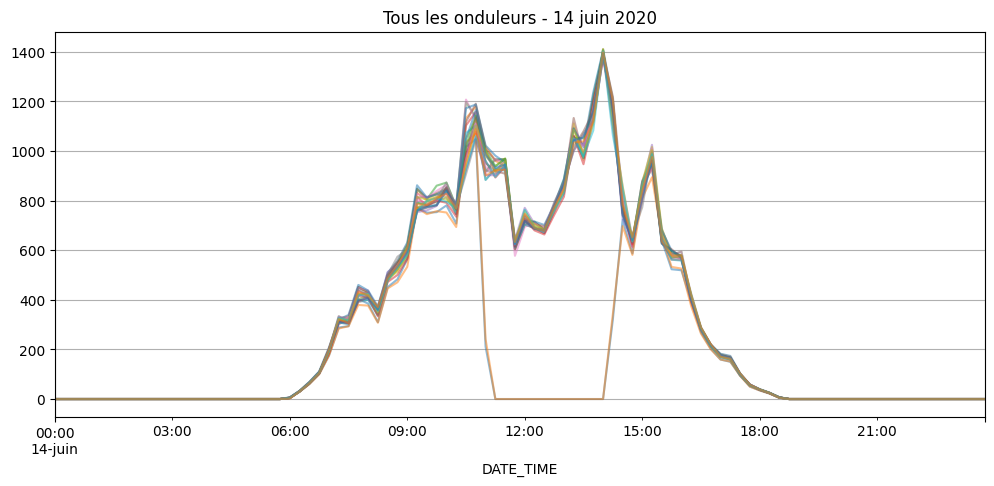

In [18]:
jour_14 = df[df["DATE_TIME"].dt.date == pd.to_datetime("2020-06-14").date()]
pivot = jour_14.pivot_table(index="DATE_TIME", columns="SOURCE_KEY", values="AC_POWER")
pivot.plot(figsize=(12, 5), legend=False, alpha=0.5)
plt.title("Tous les onduleurs - 14 juin 2020")
plt.grid(True)
plt.show()

- 14/06 : panne d'un seul onduleur (11h15-14h), irradiance normale → défaut équipement local
- Hypothèse "curtailment/coupure réseau" réfutée
- Décision de conception : cible = production agrégée centrale, pas par onduleur


In [19]:
# Détecter les anomalies sur tout le dataset
df_complet["ANOMALIE"] = (df_complet["AC_POWER"] == 0) & (df_complet["IRRADIATION"] > 0.1)

print("Nombre de points anormaux :", df_complet["ANOMALIE"].sum())
print("\nPar onduleur :")
print(df_complet[df_complet["ANOMALIE"]]["SOURCE_KEY_x"].value_counts())

Nombre de points anormaux : 63

Par onduleur :
SOURCE_KEY_x
bvBOhCH3iADSZry    20
1BY6WEcLGh8j5v7    19
z9Y9gH1T5YWrNuG     7
wCURE6d3bPkepu2     5
zBIq5rxdHJRwDNY     3
McdE0feGgRqW7Ca     3
sjndEbLyjtCKgGv     3
zVJPv84UY57bAof     2
ih0vzX44oOqAx2f     1
Name: count, dtype: int64


In [20]:
# Et par jour
print(df_complet[df_complet["ANOMALIE"]]["DATE_TIME"].dt.date.value_counts().head(10))

DATE_TIME
2020-06-07    32
2020-06-14    24
2020-05-15     2
2020-06-16     2
2020-05-24     1
2020-05-25     1
2020-06-09     1
Name: count, dtype: int64


- 14/06 : panne d'un seul onduleur (11h15-14h), irradiance normale → défaut équipement local
- Hypothèse "curtailment/coupure réseau" réfutée
- Décision de conception : cible = production agrégée centrale, pas par onduleur

In [21]:
# Croiser jour × onduleur
pd.crosstab(
    df_complet[df_complet["ANOMALIE"]]["DATE_TIME"].dt.date,
    df_complet[df_complet["ANOMALIE"]]["SOURCE_KEY_x"]
)

SOURCE_KEY_x,1BY6WEcLGh8j5v7,McdE0feGgRqW7Ca,bvBOhCH3iADSZry,ih0vzX44oOqAx2f,sjndEbLyjtCKgGv,wCURE6d3bPkepu2,z9Y9gH1T5YWrNuG,zBIq5rxdHJRwDNY,zVJPv84UY57bAof
DATE_TIME,,,,,,,,,
2020-05-15,0,0,0,0,0,0,0,0,2
2020-05-24,0,0,0,0,0,0,0,1,0
2020-05-25,0,0,0,1,0,0,0,0,0
2020-06-07,7,3,8,0,3,5,6,0,0
2020-06-09,0,0,0,0,0,0,1,0,0
2020-06-14,12,0,12,0,0,0,0,0,0
2020-06-16,0,0,0,0,0,0,0,2,0


In [22]:
# Production agrégée au niveau centrale
centrale = df.groupby("DATE_TIME")["AC_POWER"].sum().reset_index()
centrale = centrale.rename(columns={"AC_POWER": "AC_POWER_TOTAL"})
print(centrale.head())

            DATE_TIME  AC_POWER_TOTAL
0 2020-05-15 00:00:00             0.0
1 2020-05-15 00:15:00             0.0
2 2020-05-15 00:30:00             0.0
3 2020-05-15 00:45:00             0.0
4 2020-05-15 01:00:00             0.0


Construire le dataset de travail: 

In [23]:
# 1. Météo agrégée (moyenne des capteurs par horodatage)
meteo_agg = meteo.groupby("DATE_TIME")[
    ["AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]
].mean().reset_index()

# 2. Fusion production centrale + météo
data = pd.merge(centrale, meteo_agg, on="DATE_TIME", how="inner")

# 3. Vérifications
print(data.shape)
print(data.isna().sum())
print(data.describe())

(3157, 5)
DATE_TIME              0
AC_POWER_TOTAL         0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64
                        DATE_TIME  AC_POWER_TOTAL  AMBIENT_TEMPERATURE  \
count                        3157     3157.000000          3157.000000   
mean   2020-06-01 06:41:41.298701     6704.830534            25.560257   
min           2020-05-15 00:00:00        0.000000            20.398505   
25%           2020-05-23 23:15:00        0.000000            22.739895   
50%           2020-06-01 12:30:00      814.880357            24.680324   
75%           2020-06-09 18:00:00    13752.112500            27.941221   
max           2020-06-17 23:45:00    29150.212499            35.252486   
std                           NaN     8604.217954             3.351059   

       MODULE_TEMPERATURE  IRRADIATION  
count         3157.000000  3157.000000  
mean            31.175453     0.230103  
min             18.140415     0.000000  
25%             21.13

La vue d'ensemble:

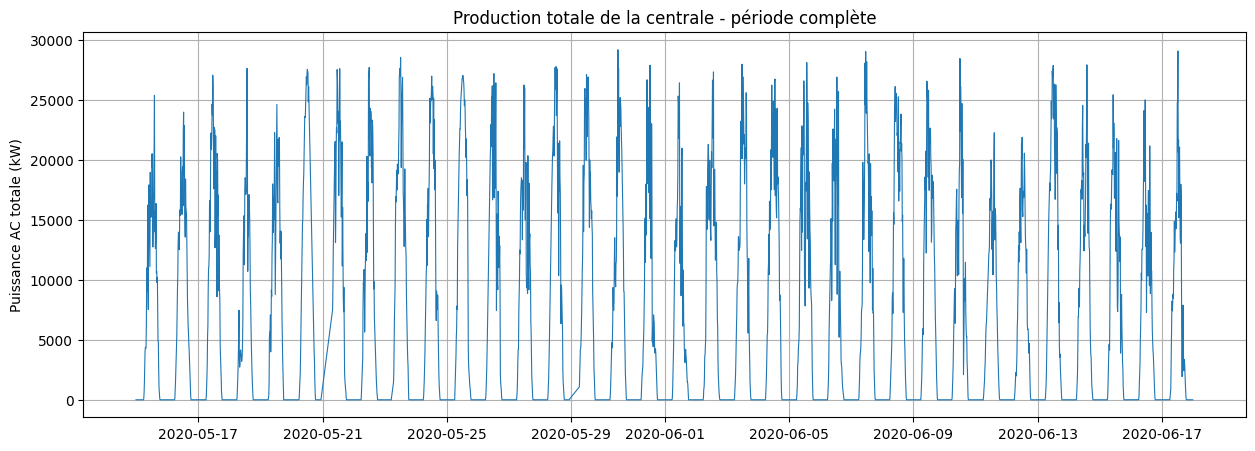

In [24]:
plt.figure(figsize=(15, 5))
plt.plot(data["DATE_TIME"], data["AC_POWER_TOTAL"], linewidth=0.8)
plt.title("Production totale de la centrale - période complète")
plt.ylabel("Puissance AC totale (kW)")
plt.grid(True)
plt.show()

In [27]:
data.to_csv("data/dataset_propre.csv", index=False)